In [2]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evaluation.py').exists())
root = ROOT
print(sorted(str(p.relative_to(root)) for p in root.rglob('company_years_h2.parquet')))

['data/company_years_h2.parquet']


In [4]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, str(ROOT))
from src.evaluation import *

import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier

X, y, groups = load_horizon(1)
fold = make_folds(y, groups)

In [5]:
def make_xgb():
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             tree_method='hist', device='cpu',       # portable default
                             eval_metric='aucpr', random_state=SEED)

res_xgb = run_cv('xgboost', 1, X, y, fold, make_model=make_xgb)

/home/shohjahon/miniconda3/envs/fastai/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [12:45:58] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


xgboost h=1 fold 0: ROC-AUC 0.924
xgboost h=1 fold 1: ROC-AUC 0.918
xgboost h=1 fold 2: ROC-AUC 0.928
xgboost h=1 fold 3: ROC-AUC 0.928
xgboost h=1 fold 4: ROC-AUC 0.923


In [6]:
def make_rf():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                max_features='sqrt', max_samples=0.2,
                                                class_weight='balanced_subsample',
                                                n_jobs=-1, random_state=SEED))

res_rf = run_cv('random_forest', 1, X, y, fold, make_model=make_rf)

random_forest h=1 fold 0: ROC-AUC 0.911
random_forest h=1 fold 1: ROC-AUC 0.901
random_forest h=1 fold 2: ROC-AUC 0.922
random_forest h=1 fold 3: ROC-AUC 0.912
random_forest h=1 fold 4: ROC-AUC 0.909


In [7]:
res_h1 = pd.concat([res_xgb, res_rf])
res_h1.to_csv(RESULTS / '04_models_h1.csv', index=False)

In [4]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT))

from src.evaluation import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
import gc, time
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

ALTMAN = {'Working_capital/total_assets': 0.717, 'Retained_profit/total_assets': 0.847,
          'EBIT/total_assets': 3.107, 'Equity/total_liabilities': 0.420,
          'Total_operating_revenue/total_assets': 0.998}

def altman_scores(Xtr, Xva, Xte):
    cols, w = list(ALTMAN), np.array(list(ALTMAN.values()))
    med = Xtr[cols].median()
    z = lambda X_: X_[cols].fillna(med).to_numpy() @ w
    return -z(Xva), -z(Xte)

def make_lr():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                         QuantileTransformer(output_distribution='normal', n_quantiles=1000,
                                             subsample=200_000, random_state=SEED),
                         LogisticRegression(class_weight='balanced', C=0.1, max_iter=2000))

def make_rf():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                         RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                max_features='sqrt', max_samples=0.2,
                                                class_weight='balanced_subsample',
                                                n_jobs=-1, random_state=SEED))

def make_xgb():
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             tree_method='hist', device='cpu',
                             eval_metric='aucpr', random_state=SEED)

MODELS = {'altman_z':      dict(score_fn=altman_scores),
          'logreg_robust': dict(make_model=make_lr),
          'random_forest': dict(make_model=make_rf),
          'xgboost':       dict(make_model=make_xgb)}

In [6]:
RESULTS.mkdir(exist_ok=True)
out = RESULTS / '04_horizons.csv'
done = pd.read_csv(out) if out.exists() else pd.DataFrame(columns=['model', 'horizon'])

for h in range(1, 6):
    X, y, groups = load_horizon(h)
    fold = make_folds(y, groups)
    print(f'\n=== horizon {h} yr: {len(y):,} rows, {y.sum():,} distressed ===')

    for name, kw in MODELS.items():
        if ((done.model == name) & (done.horizon == h)).any():
            print(f'skip {name} (already done)'); continue
        t = time.time()
        r = run_cv(name, h, X, y, fold, verbose=False, **kw)
        done = pd.concat([done, r], ignore_index=True)
        done.to_csv(out, index=False)                       # save after every model
        print(f'{name:14s} ROC-AUC {r.roc_auc.mean():.3f} ± {r.roc_auc.std():.3f}   '
              f'({(time.time() - t) / 60:.1f} min)')

    del X, y, groups, fold; gc.collect()                    # free memory before next horizon


=== horizon 1 yr: 996,500 rows, 3,054 distressed ===
altman_z       ROC-AUC 0.762 ± 0.009   (0.0 min)
logreg_robust  ROC-AUC 0.917 ± 0.005   (12.0 min)
random_forest  ROC-AUC 0.911 ± 0.007   (4.4 min)
xgboost        ROC-AUC 0.925 ± 0.004   (1.6 min)

=== horizon 2 yr: 898,692 rows, 2,374 distressed ===
altman_z       ROC-AUC 0.708 ± 0.012   (0.0 min)
logreg_robust  ROC-AUC 0.857 ± 0.005   (17.5 min)
random_forest  ROC-AUC 0.849 ± 0.005   (3.7 min)
xgboost        ROC-AUC 0.864 ± 0.007   (1.4 min)

=== horizon 3 yr: 793,234 rows, 1,896 distressed ===
altman_z       ROC-AUC 0.664 ± 0.026   (0.0 min)


/home/shohjahon/miniconda3/envs/fastai/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


logreg_robust  ROC-AUC 0.815 ± 0.004   (13.0 min)
random_forest  ROC-AUC 0.802 ± 0.013   (3.0 min)
xgboost        ROC-AUC 0.823 ± 0.014   (1.2 min)

=== horizon 4 yr: 700,041 rows, 1,485 distressed ===
altman_z       ROC-AUC 0.637 ± 0.013   (0.0 min)
logreg_robust  ROC-AUC 0.775 ± 0.012   (10.8 min)
random_forest  ROC-AUC 0.759 ± 0.010   (2.5 min)
xgboost        ROC-AUC 0.786 ± 0.010   (1.0 min)

=== horizon 5 yr: 598,832 rows, 1,154 distressed ===
altman_z       ROC-AUC 0.611 ± 0.013   (0.0 min)


/home/shohjahon/miniconda3/envs/fastai/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/shohjahon/miniconda3/envs/fastai/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-lear

logreg_robust  ROC-AUC 0.738 ± 0.008   (10.5 min)
random_forest  ROC-AUC 0.718 ± 0.009   (2.0 min)
xgboost        ROC-AUC 0.743 ± 0.007   (1.0 min)


horizon,1,2,3,4,5
model,,,,,
altman_z,0.762,0.708,0.664,0.637,0.611
logreg_robust,0.917,0.857,0.815,0.775,0.738
random_forest,0.911,0.849,0.802,0.759,0.718
xgboost,0.925,0.864,0.823,0.786,0.743


horizon,1,2,3,4,5
model,,,,,
altman_z,5.6,3.4,2.5,1.9,1.6
logreg_robust,16.3,8.3,5.6,3.7,3.0
random_forest,19.1,9.5,6.1,4.6,4.4
xgboost,22.1,10.0,7.1,5.2,4.8


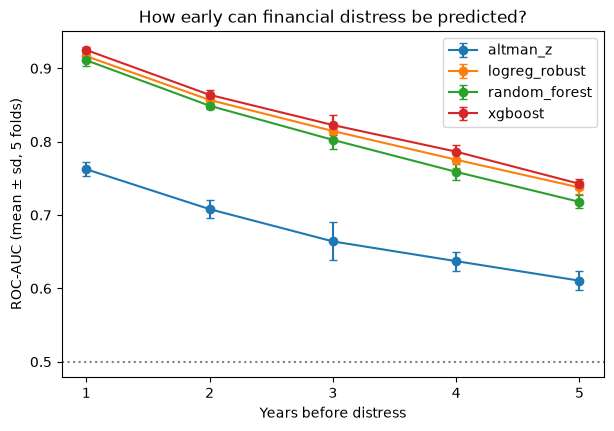

In [7]:
res = pd.read_csv(out)
res['pr_lift'] = res.pr_auc / res.pr_baseline

summ = res.groupby(['model', 'horizon']).agg(roc=('roc_auc', 'mean'), roc_sd=('roc_auc', 'std'),
                                              lift=('pr_lift', 'mean')).reset_index()
display(summ.pivot(index='model', columns='horizon', values='roc').round(3))
display(summ.pivot(index='model', columns='horizon', values='lift').round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, g in summ.groupby('model'):
    ax.errorbar(g.horizon, g.roc, yerr=g.roc_sd, marker='o', capsize=3, label=name)
ax.axhline(0.5, ls=':', color='grey')
ax.set(xlabel='Years before distress', ylabel='ROC-AUC (mean ± sd, 5 folds)',
       xticks=range(1, 6), title='How early can financial distress be predicted?')
ax.legend()
(ROOT / 'figures').mkdir(exist_ok=True)
plt.savefig(ROOT / 'figures' / 'fig5_horizon_auc.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
VARIANTS = {'xgb_plus_status':      ('operational_status',),
            'xgb_plus_year':        ('year',),
            'xgb_plus_status_year': ('operational_status', 'year')}

out_leak = RESULTS / '05_leak_test.csv'
leak = []
for h in range(1, 6):
    for name, keep in VARIANTS.items():
        X, y, groups = load_horizon(h, keep=keep)
        fold = make_folds(y, groups)               # same rows + seed -> same folds as before
        r = run_cv(name, h, X, y, fold, make_model=make_xgb, verbose=False)
        leak.append(r)
        print(f'h={h} {name:22s} ROC-AUC {r.roc_auc.mean():.3f}')
    pd.concat(leak).to_csv(out_leak, index=False)

h=1 xgb_plus_status        ROC-AUC 0.933
h=1 xgb_plus_year          ROC-AUC 0.934
h=1 xgb_plus_status_year   ROC-AUC 0.943
h=2 xgb_plus_status        ROC-AUC 0.884
h=2 xgb_plus_year          ROC-AUC 0.882
h=2 xgb_plus_status_year   ROC-AUC 0.901
h=3 xgb_plus_status        ROC-AUC 0.860
h=3 xgb_plus_year          ROC-AUC 0.847
h=3 xgb_plus_status_year   ROC-AUC 0.874
h=4 xgb_plus_status        ROC-AUC 0.830
h=4 xgb_plus_year          ROC-AUC 0.809
h=4 xgb_plus_status_year   ROC-AUC 0.849
h=5 xgb_plus_status        ROC-AUC 0.796
h=5 xgb_plus_year          ROC-AUC 0.770
h=5 xgb_plus_status_year   ROC-AUC 0.820


In [10]:
both = pd.concat([pd.read_csv(RESULTS / '04_horizons.csv').query("model == 'xgboost'"),
                  pd.read_csv(out_leak)])
display(both.pivot_table(index='model', columns='horizon', values='roc_auc').round(3))

horizon,1,2,3,4,5
model,,,,,
xgb_plus_status,0.933,0.884,0.860,0.830,0.796
xgb_plus_status_year,0.943,0.901,0.874,0.849,0.820
xgb_plus_year,0.934,0.882,0.847,0.809,0.770
xgboost,0.925,0.864,0.823,0.786,0.743


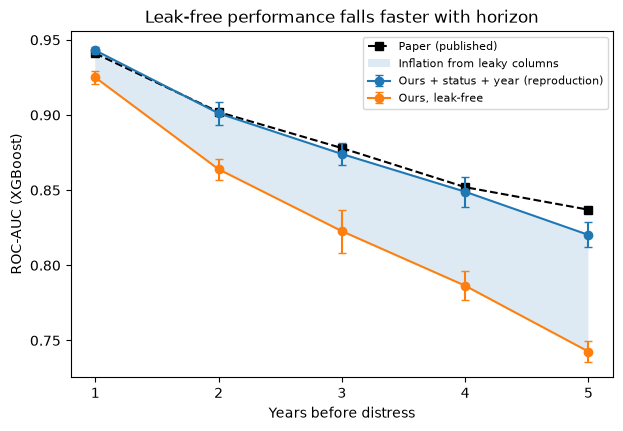

In [11]:
import matplotlib.pyplot as plt
paper = pd.Series([0.941, 0.902, 0.878, 0.852, 0.837], index=range(1, 6))
tab = both.pivot_table(index='horizon', columns='model', values='roc_auc')
sd = both.pivot_table(index='horizon', columns='model', values='roc_auc', aggfunc='std')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(paper.index, paper, 'k--', marker='s', label='Paper (published)')
for m, lab in [('xgb_plus_status_year', 'Ours + status + year (reproduction)'),
               ('xgboost', 'Ours, leak-free')]:
    ax.errorbar(tab.index, tab[m], yerr=sd[m], marker='o', capsize=3, label=lab)
ax.fill_between(tab.index, tab['xgboost'], tab['xgb_plus_status_year'], alpha=0.15,
                label='Inflation from leaky columns')
ax.set(xlabel='Years before distress', ylabel='ROC-AUC (XGBoost)', xticks=range(1, 6),
       title='Leak-free performance falls faster with horizon')
ax.legend(fontsize=8)
plt.savefig(ROOT / 'figures' / 'fig6_leak_effect.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
MODELS_DIR = ROOT / 'models'; MODELS_DIR.mkdir(exist_ok=True)

for h in range(1, 6):
    X, y, groups = load_horizon(h)
    m = make_xgb().fit(X, y)                       # all data, no test split
    m.save_model(MODELS_DIR / f'xgb_h{h}.json')    # small file, a few MB
    print(f'saved xgb_h{h}.json')
    del X, y, groups; gc.collect()

saved xgb_h1.json
saved xgb_h2.json
saved xgb_h3.json
saved xgb_h4.json
saved xgb_h5.json


In [13]:
from sklearn.model_selection import StratifiedKFold

# all firms that ever become distressed (positive in the 0-year file)
h0 = pd.read_parquet(DATA / 'company_years_h1.parquet', columns=['company', 'main_label'])
DISTRESSED = set(h0.loc[h0.main_label == 1, 'company'])

# 5-year file: distressed firms here have 6+ years of history
h5 = pd.read_parquet(DATA / 'company_years_h6.parquet', columns=['company', 'main_label'])
POS = set(h5.loc[h5.main_label == 1, 'company'])                 # same firms at every horizon
NEG = set(h5.company) - DISTRESSED                               # never-distressed firms
print(f'distressed firms total: {len(DISTRESSED):,} | with 6+ years: {len(POS):,} | healthy firms: {len(NEG):,}')

# one fold per company, reused at every horizon
comp = pd.DataFrame({'company': sorted(POS | NEG)})
comp['pos'] = comp.company.isin(POS).astype(int)
comp['fold'] = -1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, idx) in enumerate(skf.split(comp, comp.pos)):
    comp.loc[idx, 'fold'] = k
COMPANY_FOLD = comp.set_index('company').fold
del h0, h5; gc.collect()

distressed firms total: 3,587 | with 6+ years: 1,154 | healthy firms: 115,183


0

In [14]:
out_sf = RESULTS / '05_same_firm.csv'
sf = []
for h in range(1, 6):
    X, y, _ = load_horizon(h)
    meta = pd.read_parquet(DATA / f'company_years_h{h + 1}.parquet', columns=['company', 'year'])

    is_pos = (y == 1) & meta.company.isin(POS).to_numpy()
    is_neg = (y == 0) & meta.company.isin(NEG).to_numpy() & (meta.year <= 2016).to_numpy()
    keep = is_pos | is_neg

    Xs = X[keep].reset_index(drop=True)
    ys = y[keep]
    fs = meta.company[keep].map(COMPANY_FOLD).to_numpy()
    print(f'h={h}: {keep.sum():,} rows, {ys.sum():,} distressed')   # should be identical every horizon

    r = run_cv('xgb_same_firms', h, Xs, ys, fs, make_model=make_xgb, verbose=False)
    sf.append(r)
    print(f'      ROC-AUC {r.roc_auc.mean():.3f} ± {r.roc_auc.std():.3f}')
    del X, y, meta, Xs; gc.collect()

pd.concat(sf).to_csv(out_sf, index=False)

h=1: 595,554 rows, 1,154 distressed
      ROC-AUC 0.957 ± 0.004
h=2: 595,554 rows, 1,154 distressed
      ROC-AUC 0.893 ± 0.012
h=3: 595,554 rows, 1,154 distressed
      ROC-AUC 0.833 ± 0.003
h=4: 595,554 rows, 1,154 distressed
      ROC-AUC 0.797 ± 0.009
h=5: 595,554 rows, 1,154 distressed
      ROC-AUC 0.750 ± 0.011


horizon,1,2,3,4,5
model,,,,,
xgb_same_firms,0.957,0.893,0.833,0.797,0.750
xgboost,0.925,0.864,0.823,0.786,0.743


horizon,1,2,3,4,5
model,,,,,
xgb_same_firms,78.1,27.9,11.8,7.8,6.2
xgboost,22.1,10.0,7.1,5.2,4.8


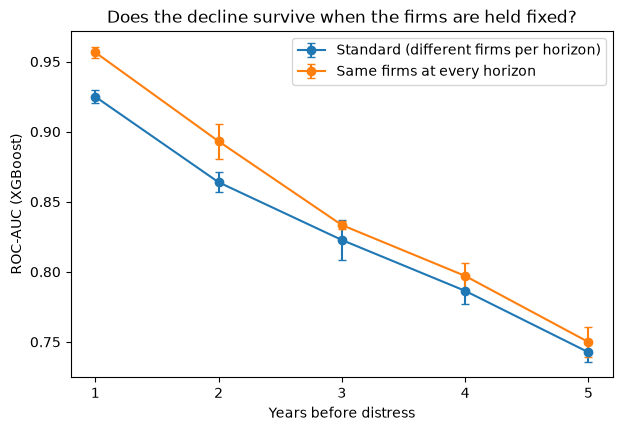

In [15]:
std = pd.read_csv(RESULTS / '04_horizons.csv').query("model == 'xgboost'")
sf_res = pd.read_csv(out_sf)
cmp = pd.concat([std, sf_res])
cmp['pr_lift'] = cmp.pr_auc / cmp.pr_baseline
display(cmp.pivot_table(index='model', columns='horizon', values='roc_auc').round(3))
display(cmp.pivot_table(index='model', columns='horizon', values='pr_lift').round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
for m, lab in [('xgboost', 'Standard (different firms per horizon)'),
               ('xgb_same_firms', 'Same firms at every horizon')]:
    g = cmp[cmp.model == m].groupby('horizon').roc_auc
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker='o', capsize=3, label=lab)
ax.set(xlabel='Years before distress', ylabel='ROC-AUC (XGBoost)', xticks=range(1, 6),
       title='Does the decline survive when the firms are held fixed?')
ax.legend()
plt.savefig(ROOT / 'figures' / 'fig7_same_firm.png', dpi=150, bbox_inches='tight'); plt.show()

In [22]:
META = {'country', 'legal_form', 'naics_2digit', 'naics_3digit', 'number_of_employees',
        'incorporation_date_1', 'incorporation_date_2', 'has_multiple_industries',
        'primary_naics_encoded', 'secondary_naics_encoded', 'sector_1', 'state'}

def family(c):
    cl = c.lower()
    if c.endswith('_Sector'):                                  return 'sector-relative'
    if 'growth' in cl:                                         return 'growth'
    if cl.startswith('log'):                                   return 'size'
    if c in META:                                              return 'company info'
    if any(k in cl for k in ['ebit', 'profit', 'loss_flag']):  return 'profitability'
    if any(k in cl for k in ['current_assets', 'cash', 'quick', 'working_capital']):
                                                               return 'liquidity'
    if any(k in cl for k in ['liabilities', 'equity', 'debt', 'constant_capital', 'insolvency']):
                                                               return 'leverage / solvency'
    return 'efficiency / turnover'

OVERRIDE = {
    'EBIT/financial_costs': 'leverage / solvency',
    'Total_liabilities-cash/EBITDA': 'leverage / solvency',
    'Interest_expense/revenue': 'leverage / solvency',
    'Total_liabilities-cash/total_operating_revenue': 'leverage / solvency',
    'Log_operating_profit/gdp': 'profitability',
    'Log_net_profit/gdp': 'profitability',
    'Short_term_liabilities_turnover_days': 'efficiency / turnover',
    'Total_operating_revenue/short_term_liabilities': 'efficiency / turnover',
    'Revenue/total_liabilities': 'efficiency / turnover',
    'Revenue/long_term_liabilities': 'efficiency / turnover',
}

X1, _, _ = load_horizon(1)                                          # 1. load first
fam_map = pd.Series({c: OVERRIDE.get(c, family(c)) for c in X1.columns})   # 2. then map, with overrides
del X1

display(fam_map.value_counts())
print('overrides applied:', fam_map[list(OVERRIDE)].to_dict())

profitability            25
liquidity                24
leverage / solvency      24
sector-relative          17
efficiency / turnover    13
company info             11
growth                    8
size                      6
Name: count, dtype: int64

overrides applied: {'EBIT/financial_costs': 'leverage / solvency', 'Total_liabilities-cash/EBITDA': 'leverage / solvency', 'Interest_expense/revenue': 'leverage / solvency', 'Total_liabilities-cash/total_operating_revenue': 'leverage / solvency', 'Log_operating_profit/gdp': 'profitability', 'Log_net_profit/gdp': 'profitability', 'Short_term_liabilities_turnover_days': 'efficiency / turnover', 'Total_operating_revenue/short_term_liabilities': 'efficiency / turnover', 'Revenue/total_liabilities': 'efficiency / turnover', 'Revenue/long_term_liabilities': 'efficiency / turnover'}


In [23]:
(ROOT / 'models').mkdir(exist_ok=True)
fam_rows, top_rows, imps = [], [], []

for h in range(1, 6):
    X, y, _ = load_horizon(h)
    m = make_xgb().fit(X, y)                                     # final model on all data
    m.save_model(ROOT / 'models' / f'xgb_h{h}.json')

    rng = np.random.default_rng(SEED)
    idx = np.sort(np.concatenate([np.flatnonzero(y == 1),
                                  rng.choice(np.flatnonzero(y == 0), 10_000, replace=False)]))
    contrib = m.get_booster().predict(xgb.DMatrix(X.iloc[idx]), pred_contribs=True)[:, :-1]  # SHAP values

    imp = pd.Series(np.abs(contrib).mean(axis=0), index=X.columns)
    imps.append(imp.rename(h))
    top_rows.append(imp.sort_values(ascending=False).head(10).index
                       .to_series(index=range(1, 11), name=f'{h} yr'))
    fam = imp.groupby(fam_map).sum()
    fam_rows.append((fam / fam.sum()).rename(h))
    print(f'h={h} done')
    del X, y, m, contrib; gc.collect()

pd.concat(imps, axis=1).to_csv(RESULTS / '06_shap_features.csv')    # per-feature, for regrouping later
fam_tab = pd.concat(fam_rows, axis=1)
fam_tab.to_csv(RESULTS / '06_shap_families.csv')

display((fam_tab * 100).round(1))                # % of total importance per family
display(pd.concat(top_rows, axis=1))             # top-10 single ratios per horizon

h=1 done
h=2 done
h=3 done
h=4 done
h=5 done


,1,2,3,4,5
company info,7.800000,9.600000,9.300000,9.600000,9.400000
efficiency / turnover,6.700000,7.300000,7.400000,7.600000,7.100000
growth,6.700000,6.200000,6.800000,7.100000,8.600000
leverage / solvency,27.500000,25.200001,21.100000,20.799999,22.200001
liquidity,20.500000,17.900000,18.200001,15.800000,15.900000
profitability,16.299999,19.100000,21.200001,18.299999,17.000000
sector-relative,10.200000,10.300000,12.700000,16.299999,15.200000
size,4.400000,4.600000,3.400000,4.600000,4.600000


,1 yr,2 yr,3 yr,4 yr,5 yr
1,Equity/total_liabilities,Total_liabilities/total_assets,Equity/total_liabilities,Total_liabilities/total_assets,EBIT/financial_costs
2,Total_liabilities/total_assets,Equity/total_liabilities,primary_naics_encoded,Equity/total_liabilities,Equity/total_assets
3,Operating_expenses/sales,primary_naics_encoded,Total_liabilities/total_assets,primary_naics_encoded,Inventories*365/revenue_Sector
4,Working_capital/fixed_assets,Equity/fixed_assets,Operating_expenses/sales,Equity-share_capital/fixed_assets,incorporation_date_1
5,primary_naics_encoded,Operating_expenses/sales,Retained_profit/total_assets,Operating_expenses/sales,Equity/total_liabilities
6,Current_assets/short_term_liabilities,Working_capital,Current_assets/short_term_liabilities,incorporation_date_1,Total_assets_growth
7,Log_operating_profit/gdp,Net_profit+depreciation/current_liabilities,country,EBITDA_margin_Sector,state
8,Working_capital/total_liabilities,country,Log_operating_profit/gdp,Working_capital/sales,Current_assets-inventories/short_term_liabilities
9,Working_capital,Working_capital/fixed_assets,Gross_profit/short_term_liabilities,Working_capital/assets_Sector,Receivables_growth
10,Current_assets/total_liabilities,Cash_flow/total_debt,Cash_flow/total_debt,Receivables*365/revenue_Sector,Interest_expense/revenue


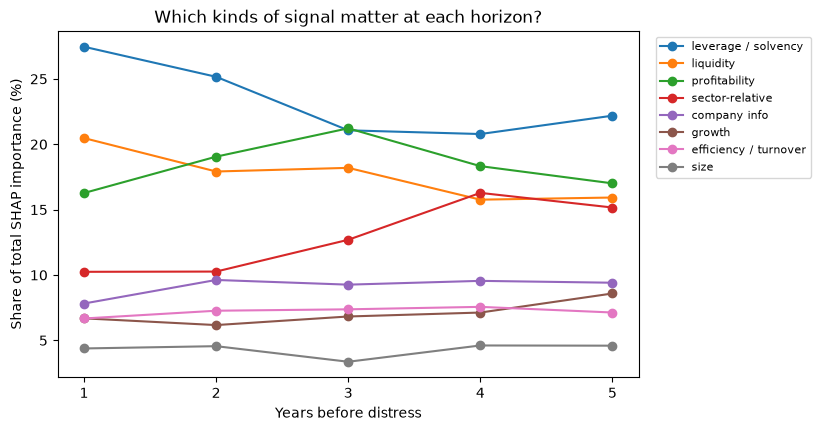

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for f in fam_tab.sort_values(1, ascending=False).index:
    ax.plot(fam_tab.columns, fam_tab.loc[f] * 100, marker='o', label=f)
ax.set(xlabel='Years before distress', ylabel='Share of total SHAP importance (%)',
       xticks=range(1, 6), title='Which kinds of signal matter at each horizon?')
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig(ROOT / 'figures' / 'fig8_shap_families.png', dpi=150, bbox_inches='tight'); plt.show()